# Minimum wages and in-work poverty in the EU: the analysis

Final project, Econometrics (ECO\_4MO11), Télécom Paris, November 2026. Yuewen Sun, Victor Zacarias and Robin Herment.

**Question.** Across the 21 EU countries with a statutory minimum wage (2009-2024), is a higher real or relative minimum wage associated with lower in-work poverty among employees, once permanent differences between countries and shocks common to all of them are held fixed?

This notebook is built from the scripts in `analysis/` by `report_code/make_notebook.py` and run from the repository root. Each section is one script. The text before a code cell says what we do and why, and the text after it gives our reading of the output. The report is `report/main.pdf`, and every number in it is written by these scripts to `output/results/`.


In [1]:
import sys
sys.path.insert(0, "analysis")   # the scripts import tools.py from there

## Step 1: get the raw data from the Eurostat database

Every series comes from the Eurostat dissemination API (JSON-stat format) and is
saved as a tidy CSV in data/raw/, one row per country, year and remaining
dimension, with Eurostat's status flag ("b" = break in series, "p" = provisional).

The repository ships the snapshot we used (downloaded 7 November 2026), so the
analysis can be reproduced without internet access. By default this script only
describes the snapshot; `python 01_get_data.py --download` replaces it with
fresh data. Eurostat revises its tables, so fresh data can move the estimates
slightly.

*Source: `analysis/01_get_data.py`*

In [2]:
import itertools
import json
import sys
import time
from datetime import date

import pandas as pd
import requests

from tools import COUNTRIES, PATH_RAW

REFRESH = "--download" in sys.argv

### 1(a) Which series do we need?

Each entry is file name -> (Eurostat table, filters). The filters fix every
dimension except country and time, and at most one or two dimensions that we
keep as columns (lists below). Definitions are in the README.

In [3]:
API = "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/"
DIVISIONS = [f"CP{k:02d}" for k in range(1, 13)]           # the 12 COICOP divisions
HOUSEHOLDS = ["A1", "A1_DCH", "A_GE2_NDCH", "A_GE2_DCH"]

SERIES = {
    # Outcome: in-work at-risk-of-poverty rate, aged 18-64, employees (SAL) and
    # all employed people (EMP), by working time and by household type.
    "inwork_poverty_employees": ("ilc_iw01", {"wstatus": "SAL", "sex": "T", "age": "Y18-64", "unit": "PC"}),
    "inwork_poverty": ("ilc_iw01", {"wstatus": "EMP", "sex": "T", "age": "Y18-64", "unit": "PC"}),
    "inwork_poverty_worktime": ("ilc_iw07", {"worktime": ["FT", "PT"], "unit": "PC"}),
    "inwork_poverty_household": ("ilc_iw02", {"hhcomp": HOUSEHOLDS, "unit": "PC"}),
    # Poverty rates at 40/50/60/70% of the median, by most frequent activity
    # status (employees, retired, unemployed), aged 18 and over.
    "poverty_by_activity": ("ilc_li04", {"wstatus": ["SAL", "RET", "UNE"],
                                         "rskpovth": ["B_40", "B_50", "B_60", "B_70"],
                                         "statinfo": "MED_EI", "sex": "T", "age": "Y_GE18", "unit": "PC"}),
    # Minimum wage: gross monthly statutory minimum wage, January (S1) and July (S2).
    "minwage_nac": ("earn_mw_cur", {"currency": "NAC"}),
    "minwage_pps": ("earn_mw_cur", {"currency": "PPS"}),
    # Kaitz index: minimum wage as % of mean or median gross monthly earnings.
    "kaitz_mean": ("earn_mw_avgr2", {"nace_r2": "B-S", "indic_se": "MMW_MEAN_ME_PP", "unit": "PC"}),
    "kaitz_median": ("earn_mw_avgr2", {"nace_r2": "B-S", "indic_se": "MMW_MED_ME_PP", "unit": "PC"}),
    # Prices: HICP, annual average index (2015 = 100), all items and by division.
    "hicp_index": ("prc_hicp_aind", {"unit": "INX_A_AVG", "coicop": "CP00"}),
    "hicp_divisions": ("prc_hicp_aind", {"unit": "INX_A_AVG", "coicop": DIVISIONS}),
    # Budget shares (per mille) of the poorest and richest income quintiles.
    "hbs_budget_shares": ("hbs_str_t223", {"quant_inc": ["QU1", "QU5"], "coicop": DIVISIONS, "unit": "PM"}),
    # Controls
    "unemployment": ("une_rt_a", {"age": "Y15-74", "sex": "T", "unit": "PC_ACT"}),
    "gdp_pc_real": ("nama_10_pc", {"na_item": "B1GQ", "unit": "CLV20_EUR_HAB"}),
    "parttime_share": ("lfsa_eppga", {"sex": "T", "age": "Y15-64", "unit": "PC"}),
    # Weights and the employment check
    "employees_thousands": ("lfsa_eegaed", {"sex": "T", "age": "Y20-64", "isced11": "TOTAL", "unit": "THS_PER"}),
    "employment_rate_low_educ": ("lfsa_ergaed", {"sex": "T", "age": "Y20-64", "isced11": "ED0-2", "unit": "PC"}),
    # Mechanisms
    "poverty_threshold": ("ilc_li01", {"statinfo": "MED_EI", "hhcomp": "A1", "rskpovth": "B_60", "unit": "NAC"}),
    "poverty_anchored_2008": ("ilc_li22b", {"statinfo": "MED_EI", "rskpovth": "B_60", "sex": "T",
                                            "age": "Y18-64", "unit": "PC"}),
    "deprivation_q1": ("ilc_mdsd02", {"hhcomp": "TOTAL", "quant_inc": "QU1", "unit": "PC"}),
}
print(len(SERIES), "series from", len({v[0] for v in SERIES.values()}), "Eurostat tables")

20 series from 16 Eurostat tables


### 1(b) Download one table

JSON-stat stores all cells in one flat list, in row-major order over the
dimensions; we rebuild the labels of each cell from that order.

In [4]:
def fetch(code, filters):
    params = {"format": "JSON", "lang": "EN", "geo": COUNTRIES, **filters}
    for attempt in range(6):                     # the API sometimes drops a connection
        try:
            r = requests.get(API + code, params=params, timeout=180)
            r.raise_for_status()
            break
        except requests.RequestException:
            if attempt == 5:
                raise
            time.sleep(5 * (attempt + 1))
    js = r.json()
    dims, sizes = js["id"], js["size"]
    labels = [sorted(js["dimension"][d]["category"]["index"].items(), key=lambda kv: kv[1]) for d in dims]
    keep = [d for d, s in zip(dims, sizes) if s > 1 or d in ("geo", "time")]
    values, status = js.get("value", {}), js.get("status", {})
    rows = []
    for flat, combo in enumerate(itertools.product(*[range(s) for s in sizes])):
        key = str(flat)
        if key not in values and key not in status:
            continue
        cell = {d: labels[k][combo[k]][0] for k, d in enumerate(dims)}
        rows.append({**{d: cell[d] for d in keep}, "value": values.get(key), "flag": status.get(key, "")})
    return pd.DataFrame(rows), js.get("updated", "")

### 1(c) Download everything (only with --download) and describe the snapshot



In [5]:
if REFRESH:
    meta = {}
    for name, (code, filters) in SERIES.items():
        df, updated = fetch(code, filters)
        df.to_csv(PATH_RAW / f"{name}.csv", index=False)
        meta[name] = {"eurostat_code": code, "filters": filters, "eurostat_updated": updated,
                      "downloaded": date.today().isoformat(), "rows": len(df)}
        print("downloaded", name)
    (PATH_RAW / "_metadata.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")

meta = json.loads((PATH_RAW / "_metadata.json").read_text(encoding="utf-8"))
summary = []
for name, m in meta.items():
    df = pd.read_csv(PATH_RAW / f"{name}.csv", dtype={"time": str})
    summary.append({"file": name, "table": m["eurostat_code"], "rows": len(df),
                    "first": df.time.min(), "last": df.time.max(), "countries": df.geo.nunique(),
                    "eurostat_updated": m["eurostat_updated"][:10], "downloaded": m["downloaded"]})
print(pd.DataFrame(summary).to_string(index=False))

                    file         table  rows   first    last  countries eurostat_updated downloaded
inwork_poverty_employees      ilc_iw01   356    2009    2025         21       2026-10-20 2026-11-07
          inwork_poverty      ilc_iw01   445    2003    2025         21       2026-10-20 2026-11-07
 inwork_poverty_worktime      ilc_iw07   890    2003    2025         21       2026-10-20 2026-11-07
inwork_poverty_household      ilc_iw02  1780    2003    2025         21       2026-10-20 2026-11-07
     poverty_by_activity      ilc_li04  2856    2009    2025         21       2026-10-20 2026-11-07
             minwage_nac   earn_mw_cur  1176 1999-S1 2026-S2         21       2026-07-31 2026-11-07
             minwage_pps   earn_mw_cur  1176 1999-S1 2026-S2         21       2026-07-31 2026-11-07
              kaitz_mean earn_mw_avgr2   340    2008    2026         21       2026-07-31 2026-11-07
            kaitz_median earn_mw_avgr2   165    2008    2026         14       2026-07-31 2026-11-07


**Interpretation.** All 21 countries are covered by every table. EU-SILC tables run up to the
2025 wave, which describes income in 2024. The Kaitz index on the median wage
exists for fewer countries and years than the one on the mean wage.

## Step 2: build the country-year panel data/panel.csv from data/raw/

One row per country and income year, 2009-2024. The cells below show how we
date the EU-SILC observations and build the real minimum wage, plus a price
index for low-income households that we use as a check.

*Source: `analysis/02_build_panel.py`*

In [6]:
import numpy as np
import pandas as pd

from tools import COUNTRIES, FIRST_YEAR, LAST_YEAR, PATH_PANEL, PATH_RAW, CONTROLS, Results

R = Results("step2")


def read(name):
    df = pd.read_csv(PATH_RAW / f"{name}.csv", dtype={"time": str})
    df["flag"] = df["flag"].fillna("")
    return df[df.value.notna()]


def by_year(name, col, lag=0, **select):
    """One series as (geo, year, col). lag=1 moves an EU-SILC wave to its income year."""
    df = read(name)
    for k, v in select.items():
        df = df[df[k] == v]
    df = df.assign(year=df.time.astype(int) - lag)
    assert not df.duplicated(["geo", "year"]).any(), name
    return df[["geo", "year", "value"]].rename(columns={"value": col})

### 2(a) Timing: date EU-SILC by income year

EU-SILC wave w asks about income in calendar year w-1 (in all countries since
Ireland aligned in 2020). A poverty rate from wave w therefore describes year
w-1, and we match it with the minimum wage of w-1. Material deprivation
describes conditions at the interview, so it keeps the survey year.

In [7]:
iw = read("inwork_poverty_employees").assign(year=lambda d: d.time.astype(int) - 1)
iw["brk"] = iw.flag.str.contains("b").astype(int)
outcomes = [
    iw[["geo", "year", "value", "brk"]].rename(columns={"value": "iwp_sal"}),
    by_year("inwork_poverty", "iwp", lag=1),
    by_year("inwork_poverty_worktime", "iwp_ft", lag=1, worktime="FT"),
    by_year("inwork_poverty_worktime", "iwp_pt", lag=1, worktime="PT"),
    by_year("inwork_poverty_household", "iwp_single", lag=1, hhcomp="A1"),
    by_year("inwork_poverty_household", "iwp_single_kids", lag=1, hhcomp="A1_DCH"),
    by_year("inwork_poverty_household", "iwp_couple_nokids", lag=1, hhcomp="A_GE2_NDCH"),
    by_year("inwork_poverty_household", "iwp_couple_kids", lag=1, hhcomp="A_GE2_DCH"),
    by_year("poverty_by_activity", "pov_sal_40", lag=1, wstatus="SAL", rskpovth="B_40"),
    by_year("poverty_by_activity", "pov_sal_50", lag=1, wstatus="SAL", rskpovth="B_50"),
    by_year("poverty_by_activity", "pov_sal_60", lag=1, wstatus="SAL", rskpovth="B_60"),
    by_year("poverty_by_activity", "pov_sal_70", lag=1, wstatus="SAL", rskpovth="B_70"),
    by_year("poverty_by_activity", "pov_retired", lag=1, wstatus="RET", rskpovth="B_60"),
    by_year("poverty_by_activity", "pov_unemployed", lag=1, wstatus="UNE", rskpovth="B_60"),
    by_year("poverty_threshold", "threshold_nac", lag=1),
    by_year("poverty_anchored_2008", "pov_anchored", lag=1),
    by_year("deprivation_q1", "depriv_q1", lag=0),              # survey-year dating
]
print("Employee in-work poverty: survey waves", iw.time.min(), "to", iw.time.max(),
      "-> income years", iw.year.min(), "to", iw.year.max())
print("Breaks flagged by Eurostat:", int(iw[iw.year.between(FIRST_YEAR, LAST_YEAR)].brk.sum()),
      "in", iw[iw.year.between(FIRST_YEAR, LAST_YEAR) & (iw.brk == 1)].geo.nunique(), "countries")

Employee in-work poverty: survey waves 2009 to 2025 -> income years 2008 to 2024
Breaks flagged by Eurostat: 19 in 11 countries


### 2(b) Real minimum wage

Gross monthly minimum wage in national currency, averaged over the January
and July values, divided by the country's own HICP (2015 = 100). We express
it in 2015 purchasing power standards (PPS) so that levels are comparable
across countries; within a country this is a constant factor, so it does not
change any estimate that has country dummies.

In [8]:
mw = read("minwage_nac").assign(year=lambda d: d.time.str[:4].astype(int))
mw = mw.groupby(["geo", "year"], as_index=False)["value"].mean().rename(columns={"value": "mw_nac"})
pps2015 = read("minwage_pps").query("time.str.startswith('2015')", engine="python").groupby("geo")["value"].mean()

grid = pd.MultiIndex.from_product([COUNTRIES, range(FIRST_YEAR - 2, LAST_YEAR + 3)],
                                  names=["geo", "year"]).to_frame(index=False)
panel = grid
for part in [mw, by_year("hicp_index", "hicp"), by_year("kaitz_mean", "kaitz"),
             by_year("kaitz_median", "kaitz_median"), by_year("unemployment", "unemp"),
             by_year("gdp_pc_real", "gdp_pc"), by_year("parttime_share", "parttime"),
             by_year("employees_thousands", "employees"),
             by_year("employment_rate_low_educ", "emp_low_educ")] + outcomes:
    panel = panel.merge(part, how="left", on=["geo", "year"])

panel["real_mw"] = panel.mw_nac / panel.hicp * 100
base = panel[panel.year == 2015].set_index("geo")
panel["real_mw_pps"] = panel.real_mw * panel.geo.map(pps2015 / base.real_mw)
panel["log_real_mw"] = np.log(panel.real_mw_pps)
panel["log_gdp_pc"] = np.log(panel.gdp_pc)
# The Kaitz index is MW / mean wage, so the mean wage it implies is MW / Kaitz.
# We use it to split the Kaitz index into its numerator and denominator.
panel["log_real_mean_wage"] = np.log(panel.mw_nac / (panel.kaitz / 100) / panel.hicp * 100)
panel["log_real_threshold"] = np.log(panel.threshold_nac / panel.hicp * 100)
chk = panel[panel.year.between(FIRST_YEAR, LAST_YEAR)]
print(chk.groupby("geo").real_mw_pps.agg(["first", "last"]).round(0).T.to_string())

geo        BE     BG     CZ      DE     EE      EL      ES      FR     HR     HU      IE     LT      LU     LV     MT      NL      PL     PT     RO      SI     SK
first  1387.0  264.0  480.0  1349.0  419.0  1004.0   832.0  1283.0  588.0  440.0  1165.0  396.0  1489.0  372.0  842.0  1335.0   586.0  660.0  296.0   745.0  460.0
last   1390.0  697.0  683.0  1487.0  682.0   892.0  1131.0  1279.0  929.0  842.0  1400.0  956.0  1642.0  658.0  898.0  1396.0  1192.0  906.0  952.0  1141.0  742.0


### 2(c) A price index for low-income households

Food and energy drove the 2022-23 inflation, and they weigh more in the
budgets of poor households. We build a fixed-weight (Laspeyres) index of the
12 HICP divisions with the budget shares of the poorest income quintile from
each country's latest Household Budget Survey wave, and the same for the
richest quintile for comparison.

In [9]:
div = read("hicp_divisions").assign(year=lambda d: d.time.astype(int))
hbs = read("hbs_budget_shares").assign(year=lambda d: d.time.astype(int))
wave = hbs.groupby("geo").year.max()
hbs = hbs[hbs.year == hbs.geo.map(wave)]
weights = hbs.pivot_table(index=["geo", "quant_inc"], columns="coicop", values="value")


def basket(q):
    w = weights.xs(q, level="quant_inc").stack().rename("w").reset_index()
    d = div.merge(w, on=["geo", "coicop"]).assign(wp=lambda x: x.w * x.value)
    g = d.groupby(["geo", "year"]).agg(wp=("wp", "sum"), w=("w", "sum"))
    return (g.wp / g.w).rename(f"p_{q.lower()}").reset_index()


panel = panel.merge(basket("QU1"), how="left", on=["geo", "year"]).merge(basket("QU5"), how="left", on=["geo", "year"])
base = panel[panel.year == 2015].set_index("geo")
for q in ["p_qu1", "p_qu5"]:
    panel[q] = panel[q] / panel.geo.map(base[q]) * 100            # 2015 = 100
panel["log_real_mw_q1"] = np.log(panel.mw_nac / panel.p_qu1 * 100 * panel.geo.map(pps2015 / base.mw_nac))
print("HBS wave used for the budget shares:", wave.value_counts().to_dict())
print("Food and housing/energy shares (per mille), poorest vs richest quintile, median country:")
print(weights[["CP01", "CP04"]].groupby(level="quant_inc").median().round(0).to_string())

HBS wave used for the budget shares: {2020: 20, 2015: 1}
Food and housing/energy shares (per mille), poorest vs richest quintile, median country:
coicop      CP01   CP04
quant_inc              
QU1        222.0  387.0
QU5        161.0  280.0


### 2(d) Leads, lags, series segments

Leads and lags of the minimum wage for the distributed-lag model (Lecture 7).
A new series segment starts at each Eurostat break in the employee series,
so we can give each segment its own level as a robustness check.

In [10]:
panel = panel.sort_values(["geo", "year"]).reset_index(drop=True)
for v in ["log_real_mw", "kaitz"]:
    g = panel.groupby("geo")[v]
    panel[f"{v}_lead1"], panel[f"{v}_lag1"] = g.shift(-1), g.shift(1)
panel["brk"] = panel.brk.fillna(0).astype(int)
panel["segment"] = panel.geo + "_" + panel.groupby("geo")["brk"].cumsum().astype(str)

panel = panel[panel.year.between(FIRST_YEAR, LAST_YEAR)].reset_index(drop=True)
assert not panel.duplicated(["geo", "year"]).any()
assert (panel.real_mw_pps.dropna() > 0).all()
panel.to_csv(PATH_PANEL, index=False)

main = panel.dropna(subset=["iwp_sal", "log_real_mw"] + CONTROLS)
print(f"Panel: {len(panel)} country-years. Main sample: {len(main)} observations, "
      f"{main.geo.nunique()} countries, income years {main.year.min()}-{main.year.max()}")
print("Missing in the main sample: Germany before 2015 (no minimum wage).",
      sorted(set(panel.geo + panel.year.astype(str)) - set(main.geo + main.year.astype(str))))
print("Observations per variable:\n" + panel.notna().sum().to_string())

R.put("NObs", len(main), 0)
R.put("NCountries", main.geo.nunique(), 0)
R.put("NBreaks", int(main.brk.sum()), 0)
R.put("NBreakCountries", main[main.brk == 1].geo.nunique(), 0)
R.put("NKaitz", main.kaitz.notna().sum(), 0)
R.put("NKaitzMedianCountries", main.dropna(subset=["kaitz_median"]).geo.nunique(), 0)
R.finish()

Panel: 336 country-years. Main sample: 330 observations, 21 countries, income years 2009-2024
Missing in the main sample: Germany before 2015 (no minimum wage). ['DE2009', 'DE2010', 'DE2011', 'DE2012', 'DE2013', 'DE2014']
Observations per variable:
geo                   336
year                  336
mw_nac                330
hicp                  336
kaitz                 303
kaitz_median          147
unemp                 336
gdp_pc                336
parttime              336
employees             336
emp_low_educ          336
iwp_sal               336
brk                   336
iwp                   336
iwp_ft                336
iwp_pt                335
iwp_single            336
iwp_single_kids       336
iwp_couple_nokids     336
iwp_couple_kids       336
pov_sal_40            231
pov_sal_50            231
pov_sal_60            231
pov_sal_70            231
pov_retired           231
pov_unemployed        229
threshold_nac         336
pov_anchored          320
depriv_q1             2

Saved 6 numbers and 0 result blocks to output/results/step2.tex/.json


**Interpretation.** The panel has 336 country-years and the main regressions use 330: the six
German years before the minimum wage started in 2015 have no minimum wage.
The Kaitz index is missing for some country-years, so Kaitz regressions use
fewer observations. Poor households spend a larger share of their budget on
food than rich ones, which is why we also deflate by their own price index.

## Step 3: descriptive statistics and motivating evidence

Before any regression we look at the data: how much the minimum wage moves
within countries, what happened in France and Germany, and whether countries
whose minimum wage grew more saw in-work poverty fall more.

*Source: `analysis/03_descriptives.py`*

In [11]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from tools import CONTROLS, Results, load_panel, sample

R = Results("step3")
df = load_panel()
main = sample(df, ["iwp_sal", "log_real_mw"] + CONTROLS)

### 3(a) Summary statistics

The "within SD" removes each country's mean. Only this variation is left once
we add country dummies, so it tells us whether there is enough to learn from.

In [12]:
VARS = {"iwp_sal": "In-work poverty, employees (%)", "iwp": "In-work poverty, all employed (%)",
        "real_mw_pps": "Real minimum wage (2015 PPS/month)", "kaitz": "Kaitz index (MW / mean wage, %)",
        "unemp": "Unemployment rate (%)", "gdp_pc": "Real GDP per capita (2020 EUR, 000s)",
        "parttime": "Part-time share of employment (%)"}
rows = {}
for v, label in VARS.items():
    s = main[v] / (1000 if v == "gdp_pc" else 1)
    rows[label] = {"N": s.count(), "Mean": s.mean(), "SD": s.std(),
                   "Within SD": (s - s.groupby(main.geo).transform("mean")).std(), "Min": s.min(), "Max": s.max()}
table1 = pd.DataFrame(rows).T
print(table1.round(2).to_string())
within_mw = (main.log_real_mw - main.groupby("geo").log_real_mw.transform("mean")).std()
print("Within-country SD of the log real minimum wage:", round(within_mw, 3))
R.store("table1", table1.reset_index(names="variable").to_dict("records"))
R.put("WithinSdMw", 100 * within_mw, 0)
R.put("WithinSdMwLog", within_mw, 2)
R.put("MeanIwpSal", main.iwp_sal.mean(), 1)
R.put("MeanIwp", main.iwp.mean(), 1)

                                          N    Mean      SD  Within SD     Min      Max
In-work poverty, employees (%)        330.0    6.29    2.42       1.05    2.50    14.70
In-work poverty, all employed (%)     330.0    8.37    3.21       1.19    3.10    19.70
Real minimum wage (2015 PPS/month)    330.0  865.24  349.99     116.75  247.45  1641.62
Kaitz index (MW / mean wage, %)       303.0   43.24    4.80       3.17   31.70    55.20
Unemployment rate (%)                 330.0    8.63    4.88       3.15    2.00    27.80
Real GDP per capita (2020 EUR, 000s)  330.0   27.83   22.36       4.41    6.89   107.57
Part-time share of employment (%)     330.0   12.63   10.30       1.30    1.40    50.80
Within-country SD of the log real minimum wage: 0.193


**Interpretation.** In-work poverty among employees averages about 6% and the real minimum wage
varies by about 19% around each country's own mean. That is a lot of
within-country variation, so a null result later cannot be blamed on a
minimum wage that never moved.

### 3(b) France and Germany, 2015-2024

France indexes its minimum wage (SMIC) automatically to prices; Germany sets
it by commission and raised it by law to EUR 12 per hour in October 2022.

In [13]:
fd = df[df.geo.isin(["FR", "DE"]) & df.year.between(2015, 2024)].copy()
fd["mw_index"] = fd.real_mw / fd.geo.map(fd[fd.year == 2015].set_index("geo").real_mw) * 100
wide = fd.pivot(index="year", columns="geo", values=["mw_index", "iwp_sal", "brk"])
print(wide.round(1).to_string())
fr, de = fd[fd.geo == "FR"].set_index("year"), fd[fd.geo == "DE"].set_index("year")
R.put("FrMwMaxDev", (fr.mw_index - 100).abs().max(), 1)
R.put("DeMwGrowth", de.loc[2024, "mw_index"] - 100, 0)
R.put("DeMwGrowthPreHike", de.loc[2021, "mw_index"] - 100, 0)
for g, s in [("Fr", fr), ("De", de)]:
    R.put(g + "IwpStart", s.loc[2015, "iwp_sal"], 1)
    R.put(g + "IwpEnd", s.loc[2024, "iwp_sal"], 1)
R.put("DeIwpNineteen", de.loc[2019, "iwp_sal"], 1)
R.put("FrIwpTwentyOne", fr.loc[2021, "iwp_sal"], 1)
R.put("FrIwpTwentyThree", fr.loc[2023, "iwp_sal"], 1)
R.put("DeIwpTwentyOne", de.loc[2021, "iwp_sal"], 1)
R.put_text("DeBreakYears", " and ".join(str(y) for y in de.index[de.brk == 1]))
es = df[df.geo == "ES"].set_index("year").real_mw
print("Spain, real minimum wage change 2018 to 2019 (%):", round(100 * (es[2019] / es[2018] - 1), 1))
R.put("EsMwJump", 100 * (es[2019] / es[2018] - 1), 0)
R.store("fr_de", fd[["geo", "year", "mw_index", "iwp_sal", "brk"]].to_dict("records"))

     mw_index        iwp_sal       brk     
geo        DE     FR      DE   FR   DE   FR
year                                       
2015    100.0  100.0     8.7  6.3  0.0  0.0
2016     99.6  100.3     8.2  5.9  0.0  0.0
2017    102.1  100.0     8.4  5.9  0.0  0.0
2018    100.3   99.2     7.3  6.2  0.0  0.0
2019    102.5   99.4     8.1  6.0  1.0  1.0
2020    101.1  100.1     7.8  4.8  0.0  0.0
2021    101.1   99.0     6.3  5.9  0.0  1.0
2022     98.4   97.7     6.1  6.0  1.0  0.0
2023    109.8   98.4     6.0  6.2  0.0  0.0
2024    110.3   98.3     6.2  6.7  0.0  0.0
Spain, real minimum wage change 2018 to 2019 (%): 21.3


**Interpretation.** France's real minimum wage stayed close to its 2015 value while Germany's
rose, mostly after October 2022. Employee in-work poverty rose slightly in
France and fell in Germany, but the German fall came in 2019-2021, before the
big increase, and in years with breaks in the German series. Two countries
cannot separate the minimum wage from everything else that changed.

### 3(c) Long differences across all 21 countries

Change in in-work poverty against the change in the log real minimum wage
between 2015 and 2024, one point per country. Robust (HC1) standard error.

In [14]:
y0, y1 = 2015, 2024
w = df[df.year.isin([y0, y1])].pivot(index="geo", columns="year", values=["iwp_sal", "log_real_mw"])
ld = pd.DataFrame({"d_iwp": w["iwp_sal"][y1] - w["iwp_sal"][y0],
                   "d_mw": 100 * (w["log_real_mw"][y1] - w["log_real_mw"][y0])}).dropna()
long_diff = smf.ols("d_iwp ~ d_mw", data=ld).fit(cov_type="HC1")
print(ld.sort_values("d_mw").round(2).T.to_string())
print(long_diff.summary().tables[1])
R.put("LdSlope", long_diff.params.d_mw, 3)
R.put("LdSe", long_diff.bse.d_mw, 3)
R.put("LdMwMax", ld.d_mw.max(), 0)
R.put_text("LdMwMaxCountry", {"RO": "Romania", "BG": "Bulgaria", "PL": "Poland"}.get(ld.d_mw.idxmax(), ld.d_mw.idxmax()))
R.put("LdMwMin", ld.d_mw.min(), 0)
R.store("long_diff", {"slope": long_diff.params.d_mw, "se": long_diff.bse.d_mw,
                      "intercept": long_diff.params.Intercept, "points": ld.reset_index().to_dict("records")})

geo      FR    BE   MT    NL    LU    DE     EL     IE    SI     PT     LV     CZ     EE    SK     ES     HU    HR     PL     BG     LT     RO
d_iwp  0.40 -0.50  3.6 -0.70 -1.00 -2.50  -2.80   0.90  -0.9  -1.40   0.10   0.70   0.40  -0.4  -0.50  -1.20   1.2  -2.70  -0.10  -1.00  -1.50
d_mw  -1.72  2.82  4.4  5.71  6.91  9.77  14.03  20.65  21.5  28.53  29.12  30.19  30.43  32.1  34.86  42.24  45.9  49.55  60.64  67.34  83.55


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0956      0.619     -0.155      0.877      -1.308       1.117
d_mw          -0.0128      0.013     -0.969      0.332      -0.039       0.013


**Interpretation.** Countries whose real minimum wage grew more did not see in-work poverty fall
more: the slope is about zero. This is a raw comparison with no controls,
but it already points in the direction of the regression results.

### 3(d) Romania: employees versus all employed people

The minimum wage covers employees but not the self-employed. In Romania the
poverty rates of these two groups are much further apart than elsewhere.

In [15]:
ro = df[df.geo == "RO"].set_index("year")
gap = (df.iwp - df.iwp_sal).groupby(df.geo).mean()
print(ro.loc[[2015, 2024], ["iwp", "iwp_sal", "real_mw"]])
print("Average gap (all employed minus employees), by country:\n", gap.round(1).sort_values().to_string())
R.put("RoIwpStart", ro.loc[2015, "iwp"], 1)
R.put("RoIwpEnd", ro.loc[2024, "iwp"], 1)
R.put("RoSalStart", ro.loc[2015, "iwp_sal"], 1)
R.put("RoSalEnd", ro.loc[2024, "iwp_sal"], 1)
R.put("RoMwGrowth", 100 * (ro.loc[2024, "real_mw"] / ro.loc[2015, "real_mw"] - 1), 0)
R.put("RoGap", gap["RO"], 0)
R.put("OtherGap", gap.drop("RO").median(), 1)

       iwp  iwp_sal      real_mw
year                            
2015  18.6      5.8  1012.500000
2024  10.7      4.3  2334.734174
Average gap (all employed minus employees), by country:
 geo
HU     0.2
BG     0.4
LU     0.5
DE     0.6
CZ     0.8
HR     1.0
LT     1.1
MT     1.1
BE     1.2
IE     1.2
NL     1.3
LV     1.4
FR     1.5
SK     1.8
EE     1.9
SI     2.1
ES     2.2
PT     2.5
PL     4.4
EL     4.6
RO    11.1


**Interpretation.** In Romania in-work poverty among all workers fell much more than among
employees, so most of the fall happened outside wage employment. Romania's
real minimum wage also grew the most, so regressions for all employed
people may pick up this compositional change. This is why our main outcome
is the employee rate.

### 3(e) Two facts about prices and the 2022-23 inflation

How did real minimum wages change from 2021 to 2023? And did prices rise
faster for the poorest fifth of households than for the richest fifth?

In [16]:
s = df[df.year.isin([2021, 2023])].pivot(index="geo", columns="year", values="real_mw").dropna()
surge = (100 * (s[2023] / s[2021] - 1)).sort_values()
print("Real minimum wage, % change 2021-2023:\n", surge.round(1).to_string())
c = df[df.year.isin([2020, 2024])].pivot(index="geo", columns="year", values=["p_qu1", "p_qu5"])
q_gap = 100 * (c["p_qu1"][2024] / c["p_qu1"][2020] - 1) - 100 * (c["p_qu5"][2024] / c["p_qu5"][2020] - 1)
print("Price rise 2020-2024, poorest minus richest quintile (points):\n", q_gap.round(1).sort_values().to_string())
R.put("SurgeFr", surge["FR"], 1, sign=True)
R.put("SurgeMin", surge.min(), 1, sign=True)
R.put("SurgeMax", surge.max(), 1, sign=True)
names = {"CZ": "Czechia", "DE": "Germany", "EE": "Estonia", "LV": "Latvia", "SK": "Slovakia", "HU": "Hungary"}
R.put_text("SurgeMinCountry", names.get(surge.idxmin(), surge.idxmin()))
R.put_text("SurgeMaxCountry", names.get(surge.idxmax(), surge.idxmax()))
R.put("BasketCountries", (q_gap > 0).sum(), 0)
R.put("BasketGapMedian", q_gap.median(), 1)
R.store("surge", surge.to_dict())
R.finish()

Real minimum wage, % change 2021-2023:
 geo
CZ   -11.4
SK    -9.7
MT    -5.1
EE    -4.7
LV    -3.0
IE    -2.6
ES    -2.2
BG    -2.1
FR    -0.7
LU    -0.2
NL    -0.2
SI     0.2
PT     0.4
PL     0.8
EL     0.9
LT     1.3
HR     3.5
HU     4.7
BE     6.5
RO     7.7
DE     8.7


Price rise 2020-2024, poorest minus richest quintile (points):
 geo
EE   -1.7
SK   -0.5
HU   -0.2
LU   -0.0
HR    0.5
FR    0.7
DE    0.8
ES    0.9
PT    1.0
BE    1.5
EL    1.5
NL    1.7
MT    2.2
SI    2.3
RO    2.6
BG    3.4
LT    3.6
PL    3.9
CZ    3.9
IE    4.5
LV    6.0
Saved 36 numbers and 4 result blocks to output/results/step3.tex/.json


**Interpretation.** Real minimum wages moved in very different directions during the inflation
surge, which is useful variation for the panel. Prices also rose faster for
the poorest fifth of households in most countries, so deflating by the
general HICP may overstate their real minimum wage; step 5 checks this.

## Step 4: main regressions

Model (1) of the report, for country i and income year t:

    IWP_it = beta * MW_it + gamma' X_it + alpha_i + delta_t + u_it

IWP is in-work poverty among employees (percentage points). MW is the log real
minimum wage or the Kaitz index. X holds the unemployment rate, log real GDP
per capita and the part-time share. alpha_i are country dummies and delta_t
year dummies. Standard errors are clustered by country; every coefficient of
interest also gets a wild cluster bootstrap p-value (p_boot).

*Source: `analysis/04_main_regressions.py`*

In [17]:
import numpy as np
import pandas as pd

from tools import (CONTROLS, Results, coef, fit, load_panel, mde, sample, show, twfe,
                   wild_cluster_p, within_r2)

R = Results("step4")
df = load_panel()
base = ["iwp_sal", "log_real_mw"] + CONTROLS
d_mw = sample(df, base)
d_k = sample(df, base + ["kaitz"])
d_all = sample(df, base + ["iwp"])
d_all_k = sample(df, base + ["iwp", "kaitz"])

### 4(a) From pooled OLS to two-way fixed effects

Column (1) compares countries with each other. Rich countries have higher
minimum wages and lower poverty for many other reasons (benefits, family
structure), so the pooled slope suffers from omitted variable bias.
Country dummies (2) keep only changes within a country; year dummies (3)
remove shocks common to all countries, such as COVID or the 2022 energy
prices. Column (4) is our main specification.

In [18]:
SPECS = {
    "(1)": ("iwp_sal ~ log_real_mw", d_mw),
    "(2)": ("iwp_sal ~ log_real_mw + " + " + ".join(CONTROLS) + " + C(geo)", d_mw),
    "(3)": (twfe("iwp_sal", "log_real_mw", controls=False), d_mw),
    "(4)": (twfe("iwp_sal", "log_real_mw"), d_mw),
    "(5)": (twfe("iwp_sal", "kaitz"), d_k),
    "(6)": (twfe("iwp_sal", ["log_real_mw", "kaitz"]), d_k),
    "(7)": (twfe("iwp", "log_real_mw"), d_all),
    "(8)": (twfe("iwp", "kaitz"), d_all_k),
}
results, fits = {}, {}
for key, (formula, data) in SPECS.items():
    res = fit(formula, data)
    fits[key] = res
    entry = {"formula": formula, "n": int(res.nobs), "within_r2": within_r2(res, formula, data) if "C(" in formula else None}
    for v in ["log_real_mw", "kaitz"]:
        if v in res.params:
            entry[v] = coef(res, v, wild_cluster_p(formula, data, v))
    year_terms = [t for t in res.params.index if t.startswith("C(year)")]
    if year_terms:
        entry["F_year_p"] = float(res.f_test(" = 0, ".join(year_terms) + " = 0").pvalue)
    ctrl = [c for c in CONTROLS if c in res.params]
    if ctrl:
        entry["F_controls_p"] = float(res.f_test(", ".join(f"{c} = 0" for c in ctrl)).pvalue)
    results[key] = entry
show({f"{k} {v}": results[k][v] for k in results for v in ["log_real_mw", "kaitz"] if v in results[k]})
print(pd.DataFrame({k: {"within R2": e["within_r2"], "F year p": e.get("F_year_p"),
                        "F controls p": e.get("F_controls_p")} for k, e in results.items()}).round(3).to_string())
r4 = fits["(4)"]
keep = ["log_real_mw"] + CONTROLS
print("Column (4), slopes (country and year dummies not shown):")
print(pd.DataFrame({"coef": r4.params[keep], "cluster SE": r4.bse[keep], "t": r4.tvalues[keep],
                    "p (t, 20 df)": r4.pvalues[keep]}).round(3).to_string())
R.store("ladder", results)

                     b     se  ci_lo  ci_hi      p  p_boot      n
(1) log_real_mw -0.465  1.220 -3.010  2.081  0.707   0.747  330.0
(2) log_real_mw -0.330  1.047 -2.515  1.854  0.756   0.766  330.0
(3) log_real_mw -0.144  1.275 -2.804  2.516  0.911   0.907  330.0
(4) log_real_mw -0.251  1.259 -2.877  2.376  0.844   0.851  330.0
(5) kaitz       -0.050  0.039 -0.130  0.030  0.209   0.207  303.0
(6) log_real_mw  0.147  1.723 -3.447  3.741  0.933   0.942  303.0
(6) kaitz       -0.054  0.056 -0.171  0.064  0.354   0.409  303.0
(7) log_real_mw -1.575  2.084 -5.922  2.771  0.458   0.638  330.0
(8) kaitz       -0.131  0.067 -0.270  0.008  0.064   0.110  303.0
               (1)    (2)    (3)    (4)    (5)    (6)    (7)    (8)
within R2     None  0.018  0.000  0.005  0.023  0.023  0.056  0.126
F year p      None    NaN  0.052  0.188  0.090  0.085  0.003  0.017
F controls p  None  0.297    NaN  0.862  0.631  0.759  0.467  0.476
Column (4), slopes (country and year dummies not shown):
           

**Interpretation.** Every estimate for employees is small relative to its standard error and
none is significant. The pooled slope and the fixed effects slopes have the
same sign but different sizes, as expected if countries differ in ways the
pooled model ignores. The year dummies are jointly significant at 10%
without controls (column 3) but not once the controls are added (column 4).

### 4(b) Reading the main coefficient (column 4)

Level-log form: a 10% higher real minimum wage changes in-work poverty by
about beta/10 percentage points. We also report the 95% interval, the
minimum detectable effect (80% power, 5% test) and the within R^2.

In [19]:
m = results["(4)"]["log_real_mw"]
per10 = {k: m[k] * 0.1 for k in ["b", "se", "ci_lo", "ci_hi"]}
mean_iwp = d_mw.iwp_sal.mean()
print("Coefficient:", round(m["b"], 3), "SE", round(m["se"], 3), "p", round(m["p"], 3), "p_boot", round(m["p_boot"], 3))
print("Per +10%:", {k: round(v, 3) for k, v in per10.items()})
print("Lower bound as % of mean in-work poverty:", round(100 * per10["ci_lo"] / mean_iwp, 1))
print("Minimum detectable effect per +10%:", round(mde(per10["se"]), 3))
R.put("MainB", m["b"], 2); R.put("MainSe", m["se"], 2); R.put("MainPboot", m["p_boot"], 2)
R.put("MainTen", per10["b"], 2); R.put("MainTenLo", per10["ci_lo"], 2); R.put("MainTenHi", per10["ci_hi"], 2, sign=True)
R.put("MainLoPctMean", -100 * per10["ci_lo"] / mean_iwp, 0)
R.put("MainMde", mde(per10["se"]), 2)
R.put("MainWithinR", results["(4)"]["within_r2"], 3)
R.put("MainFControlsP", results["(4)"]["F_controls_p"], 2)
R.put("MainFYearP", results["(4)"]["F_year_p"], 2)
R.put("NoCtrlFYearP", results["(3)"]["F_year_p"], 2)

Coefficient: -0.251 SE 1.259 p 0.844 p_boot 0.851
Per +10%: {'b': np.float64(-0.025), 'se': np.float64(0.126), 'ci_lo': -0.288, 'ci_hi': 0.238}
Lower bound as % of mean in-work poverty: -4.6
Minimum detectable effect per +10%: 0.371


**Interpretation.** The point estimate is close to zero and the 95% interval excludes large
reductions: at its lower end, a 10% higher minimum wage would lower
in-work poverty by less than 5% of its mean. The regressors explain almost
none of the within-country variation, and the controls are jointly
insignificant.

### 4(c) The relative minimum wage: Kaitz index

A relative poverty line may respond to the minimum wage relative to other
wages rather than to its purchasing power, so we also use the Kaitz index
(minimum wage as % of the mean wage), alone (5) and with the real wage (6).

In [20]:
k5 = results["(5)"]["kaitz"]
print("Kaitz (5):", {x: round(k5[x], 3) for x in ["b", "se", "ci_lo", "ci_hi", "p", "p_boot"]})
print("Both (6):", {v: round(results["(6)"][v]["b"], 3) for v in ["log_real_mw", "kaitz"]},
      {v: round(results["(6)"][v]["p_boot"], 2) for v in ["log_real_mw", "kaitz"]})
R.put("KaitzB", k5["b"], 2); R.put("KaitzLo", k5["ci_lo"], 2); R.put("KaitzHi", k5["ci_hi"], 2, sign=True)
R.put("KaitzPboot", k5["p_boot"], 2); R.put("KaitzMde", mde(k5["se"]), 2)

Kaitz (5): {'b': np.float64(-0.05), 'se': np.float64(0.039), 'ci_lo': -0.13, 'ci_hi': 0.03, 'p': 0.209, 'p_boot': 0.207}
Both (6): {'log_real_mw': np.float64(0.147), 'kaitz': np.float64(-0.054)} {'log_real_mw': 0.94, 'kaitz': 0.41}


**Interpretation.** One more point of Kaitz index goes with 0.05 points less in-work poverty,
not significant, and adding both measures together changes nothing.

### 4(d) All employed people and the role of Romania

For all employed people (self-employed included) the estimates are more
negative. We re-estimate the four headline models without Romania, the
country where in-work poverty fell mostly outside wage employment (step 3).

In [21]:
no_ro = {}
for key in ["(4)", "(5)", "(7)", "(8)"]:
    formula, data = SPECS[key]
    v = "kaitz" if key in ("(5)", "(8)") else "log_real_mw"
    dr = data[data.geo != "RO"]
    no_ro[key] = coef(fit(formula, dr), v, wild_cluster_p(formula, dr, v))
show({k + " " + ("with RO"): results[k]["kaitz" if k in ("(5)", "(8)") else "log_real_mw"] for k in no_ro})
show({k + " without RO": e for k, e in no_ro.items()})
R.store("no_romania", no_ro)
a7, a8 = results["(7)"]["log_real_mw"], results["(8)"]["kaitz"]
R.put("AllTen", a7["b"] * 0.1, 2); R.put("AllTenNoRo", no_ro["(7)"]["b"] * 0.1, 2, sign=True)
R.put("AllKaitz", a8["b"], 2); R.put("AllKaitzP", a8["p"], 2); R.put("AllKaitzPboot", a8["p_boot"], 2)
R.put("AllKaitzNoRo", no_ro["(8)"]["b"], 2)
R.put("MainTenNoRo", no_ro["(4)"]["b"] * 0.1, 2, sign=True)

                 b     se  ci_lo  ci_hi      p  p_boot      n
(4) with RO -0.251  1.259 -2.877  2.376  0.844   0.851  330.0
(5) with RO -0.050  0.039 -0.130  0.030  0.209   0.207  303.0
(7) with RO -1.575  2.084 -5.922  2.771  0.458   0.638  330.0
(8) with RO -0.131  0.067 -0.270  0.008  0.064   0.110  303.0
                    b     se  ci_lo  ci_hi      p  p_boot      n
(4) without RO  0.494  1.792 -3.256  4.244  0.786   0.801  314.0
(5) without RO -0.041  0.047 -0.138  0.057  0.395   0.400  287.0
(7) without RO  1.236  1.703 -2.330  4.801  0.477   0.519  314.0
(8) without RO -0.049  0.043 -0.140  0.041  0.267   0.255  287.0


**Interpretation.** Without Romania the estimates for all employed people move to about zero,
while those for employees barely change. The more negative all-employed
estimates reflect the fall of poverty among Romania's self-employed.

### 4(e) Comparison with the simulations behind the Directive

The JRC microsimulation (Gruenberger et al. 2021) predicts that raising every
statutory minimum wage to 50% of the gross average wage would cut in-work
poverty by 12-13% on average. What do our estimates imply for the same move?
We take the 2019 Kaitz index (MW / mean wage), compute the rise needed to
reach 50% in each country, and apply the main coefficients (columns 4 and 5).

In [22]:
k19 = df[df.year == 2019].set_index("geo")[["kaitz", "iwp_sal"]].dropna()
k19["dlog"] = np.log(50 / k19.kaitz).clip(lower=0)            # needed log increase
k19["dpts"] = (50 - k19.kaitz).clip(lower=0)                  # needed Kaitz points
below = k19[k19.kaitz < 50]
print(f"{len(below)} of {len(k19)} countries below 50% in 2019; mean needed increase "
      f"{100 * (np.exp(below.dlog) - 1).mean():.1f}%")
sim = {}
for name, key, var, col in [("real minimum wage", "(4)", "log_real_mw", "dlog"), ("Kaitz index", "(5)", "kaitz", "dpts")]:
    e = results[key][var]
    rel = {b: 100 * (e[b] * k19[col] / k19.iwp_sal).mean() for b in ["b", "ci_lo", "ci_hi"]}
    sim[name] = rel
    print(f"Implied average change in in-work poverty using the {name}: {rel['b']:.1f}% "
          f"(95% CI {rel['ci_lo']:.1f}% to {rel['ci_hi']:.1f}%)")
R.store("jrc_comparison", {"countries_below": len(below), "countries": len(k19),
                           "mean_needed_increase": 100 * (np.exp(below.dlog) - 1).mean(), "implied": sim})
R.put("SimBelow", len(below), 0); R.put("SimCountries", len(k19), 0)
R.put("SimIncrease", 100 * (np.exp(below.dlog) - 1).mean(), 0)
R.put("SimMw", -sim["real minimum wage"]["b"], 1)
R.put("SimMwLo", -sim["real minimum wage"]["ci_lo"], 1)
R.put("SimMwHi", sim["real minimum wage"]["ci_hi"], 1)
R.put("SimK", -sim["Kaitz index"]["b"], 1)
R.put("SimKLo", -sim["Kaitz index"]["ci_lo"], 1)
R.put("SimKHi", sim["Kaitz index"]["ci_hi"], 1)
R.finish()

17 of 20 countries below 50% in 2019; mean needed increase 15.7%
Implied average change in in-work poverty using the real minimum wage: -0.6% (95% CI -6.5% to 5.3%)
Implied average change in in-work poverty using the Kaitz index: -5.1% (95% CI -13.4% to 3.1%)
Saved 33 numbers and 3 result blocks to output/results/step4.tex/.json


**Interpretation.** Reaching 50% of the average wage would have required raising minimum wages
by about 16% on average in 2019 (among the countries below 50%). With the real minimum wage coefficient this
implies an average fall in in-work poverty of well under 1%, and the 95%
interval excludes the 12-13% of the simulations. With the Kaitz index the
implied fall is about 5%, and the simulated value sits at the edge of the
interval. The simulations hold behaviour and other policies fixed; our
estimates include whatever adjustment happened in practice.

## Step 5: residual diagnostics and robustness checks

Each check changes one thing in the main model (column 4 or 5 of step 4) and
reports the change in employee in-work poverty for a 10% higher real minimum
wage and for a one-point higher Kaitz index. The lecture each idea comes from
is given in brackets.

*Source: `analysis/05_diagnostics_robustness.py`*

In [23]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
import matplotlib.pyplot as plt

from tools import (CONTROLS, Results, coef, fit, load_panel, sample, save_plot, show, twfe,
                   wild_cluster_p)

R = Results("step5")
df = load_panel()
Y = "iwp_sal"
d_mw = sample(df, [Y, "log_real_mw"] + CONTROLS)
d_k = sample(df, [Y, "kaitz"] + CONTROLS)


def both(f_mw, data_mw, f_k=None, data_k=None, v_mw="log_real_mw", v_k="kaitz", w_mw=None, w_k=None):
    """Estimate one check for the real minimum wage (per +10%) and the Kaitz index."""
    out = {}
    if f_mw is not None:
        out["mw"] = coef(fit(f_mw, data_mw, w_mw), v_mw, wild_cluster_p(f_mw, data_mw, v_mw, w_mw), 0.1)
    if f_k is not None:
        out["k"] = coef(fit(f_k, data_k, w_k), v_k, wild_cluster_p(f_k, data_k, v_k, w_k))
    return out

### 5(a) Heteroskedasticity (Lecture 6)

Breusch-Pagan: regress the squared OLS residuals on all regressors; the
special White test uses the fitted values and their square. Under
homoskedasticity n*R^2 is chi-squared.

Breusch-Pagan LM = 95.3 (39 df), p = 1.3e-06
Special White LM = 16.2 (2 df), p = 0.00031
Residual SD by country:
 geo
BE    0.35
NL    0.35
CZ    0.45
FR    0.51
IE    0.58
RO    0.61
LV    0.69
HR    0.72
SI    0.75
PT    0.77
ES    0.90
EE    0.95
DE    1.08
MT    1.10
EL    1.18
LT    1.30
PL    1.35
LU    1.50
BG    1.60
SK    1.64
HU    1.77


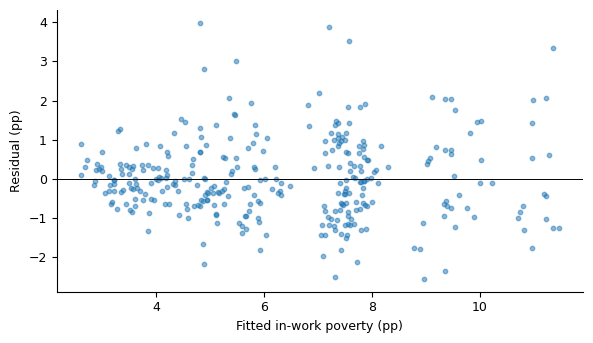

In [24]:
plain = smf.ols(twfe(Y, "log_real_mw"), d_mw).fit()
lm_bp, p_bp, _, _ = het_breuschpagan(plain.resid, plain.model.exog)
df_bp = np.linalg.matrix_rank(plain.model.exog) - 1
aux = smf.ols("u2 ~ yhat + I(yhat ** 2)", pd.DataFrame({"u2": plain.resid ** 2, "yhat": plain.fittedvalues})).fit()
lm_w = len(d_mw) * aux.rsquared
p_w = stats.chi2.sf(lm_w, 2)
print(f"Breusch-Pagan LM = {lm_bp:.1f} ({df_bp} df), p = {p_bp:.2g}")
print(f"Special White LM = {lm_w:.1f} (2 df), p = {p_w:.2g}")
sd_by_country = plain.resid.groupby(d_mw.geo).std().sort_values()
print("Residual SD by country:\n", sd_by_country.round(2).to_string())
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(plain.fittedvalues, plain.resid, s=10, alpha=0.5)
ax.axhline(0, color="black", lw=0.7)
ax.set(xlabel="Fitted in-work poverty (pp)", ylabel="Residual (pp)")
save_plot(fig, "step5_residuals_vs_fitted.png")
R.put("BpLm", lm_bp, 1); R.put("BpDf", df_bp, 0); R.put("WhiteLm", lm_w, 1)
R.put("ResSdMin", sd_by_country.min(), 2); R.put("ResSdMax", sd_by_country.max(), 1)
R.store("heteroskedasticity", {"bp": {"LM": lm_bp, "df": int(df_bp), "p": p_bp}, "white": {"LM": lm_w, "p": p_w},
                               "resid_sd": sd_by_country.to_dict()})

**Interpretation.** Both tests reject constant variance. The residual spread differs a lot by
country: the poverty series of some countries are much noisier than others.
OLS is still unbiased, but its usual standard errors are wrong, so
we use cluster-robust standard errors, which are also robust to
heteroskedasticity. Step 5(c) tries WLS and FGLS.

### 5(b) Serial correlation (Lecture 7)

Regress each residual on the previous year's residual of the same country.

In [25]:
u = d_mw.assign(u=plain.resid).sort_values(["geo", "year"])
u["u_lag"] = u.groupby("geo").u.shift(1)
ar = fit("u ~ u_lag - 1", u.dropna(subset=["u_lag"]))
print(f"Residual AR(1): rho = {ar.params.u_lag:.2f} (SE {ar.bse.u_lag:.2f})")
R.put("ArRho", ar.params.u_lag, 2)
R.store("ar1", {"rho": ar.params.u_lag, "se": ar.bse.u_lag})

Residual AR(1): rho = 0.55 (SE 0.05)


**Interpretation.** The residuals are strongly positively autocorrelated: a country with
unexpectedly high poverty one year tends to have it the next year too.
Standard errors that assume independent observations would be far too
small. Clustering by country allows any correlation within a country.

### 5(c) Weighted least squares and FGLS (Lecture 6)

Two ways to reweight. WLS by the number of employees gives the effect for
the average EU employee instead of the average country. FGLS weights each
country by the inverse of its residual variance from 5(a), so noisy series
count less. Standard errors stay cluster-robust in case the variance model
is wrong.

In [26]:
weights = {}
for name, data, v in [("mw", d_mw, "log_real_mw"), ("k", d_k, "kaitz")]:
    resid = smf.ols(twfe(Y, v), data).fit().resid
    weights[name] = 1 / (resid ** 2).groupby(data.geo).transform("mean")
wls = both(twfe(Y, "log_real_mw"), d_mw, twfe(Y, "kaitz"), d_k, w_mw=d_mw.employees, w_k=d_k.employees)
fgls = both(twfe(Y, "log_real_mw"), d_mw, twfe(Y, "kaitz"), d_k, w_mw=weights["mw"], w_k=weights["k"])
show({"WLS (employees), MW": wls["mw"], "WLS (employees), Kaitz": wls["k"],
      "FGLS, MW": fgls["mw"], "FGLS, Kaitz": fgls["k"]})
share = (weights["mw"].groupby(d_mw.geo).sum() / weights["mw"].sum()).sort_values(ascending=False)
print("FGLS weight share by country (%):", (100 * share).round(1).head(6).to_dict())
loo_fgls = {}
for g in sorted(d_mw.geo.unique()):
    dd = d_mw[d_mw.geo != g]
    w = 1 / (smf.ols(twfe(Y, "log_real_mw"), dd).fit().resid ** 2).groupby(dd.geo).transform("mean")
    loo_fgls[g] = fit(twfe(Y, "log_real_mw"), dd, w).params["log_real_mw"] * 0.1
print("FGLS per +10%, leaving one country out:", {g: round(b, 3) for g, b in loo_fgls.items()})
R.put("FglsTen", fgls["mw"]["b"], 2); R.put("FglsTenP", fgls["mw"]["p"], 2); R.put("FglsTenPboot", fgls["mw"]["p_boot"], 2)
R.put("FglsK", fgls["k"]["b"], 3); R.put("FglsKSe", fgls["k"]["se"], 3); R.put("FglsKPboot", fgls["k"]["p_boot"], 2)
R.put("FglsTopShare", 100 * share.iloc[:4].sum(), 0)
R.put("FglsNoRo", loo_fgls["RO"], 2, sign=True); R.put("FglsNoIe", loo_fgls["IE"], 2, sign=True)
R.put("WlsTen", wls["mw"]["b"], 2); R.put("WlsK", wls["k"]["b"], 2); R.put("WlsKPboot", wls["k"]["p_boot"], 2)
R.store("weighted", {"wls": wls, "fgls": fgls, "fgls_share": share.to_dict(), "fgls_loo": loo_fgls})

                            b     se  ci_lo  ci_hi      p  p_boot      n
WLS (employees), MW    -0.032  0.106 -0.252  0.189  0.767   0.762  330.0
WLS (employees), Kaitz -0.089  0.031 -0.153 -0.024  0.010   0.018  303.0
FGLS, MW               -0.103  0.042 -0.191 -0.015  0.024   0.188  330.0
FGLS, Kaitz            -0.055  0.021 -0.098 -0.012  0.015   0.030  303.0
FGLS weight share by country (%): {'BE': 18.1, 'NL': 18.1, 'CZ': 10.8, 'FR': 8.5, 'IE': 6.6, 'RO': 5.9}


FGLS per +10%, leaving one country out: {'BE': np.float64(-0.119), 'BG': np.float64(-0.137), 'CZ': np.float64(-0.1), 'DE': np.float64(-0.106), 'EE': np.float64(-0.111), 'EL': np.float64(-0.118), 'ES': np.float64(-0.102), 'FR': np.float64(-0.103), 'HR': np.float64(-0.105), 'HU': np.float64(-0.114), 'IE': np.float64(-0.033), 'LT': np.float64(-0.07), 'LU': np.float64(-0.1), 'LV': np.float64(-0.095), 'MT': np.float64(-0.062), 'NL': np.float64(-0.099), 'PL': np.float64(-0.082), 'PT': np.float64(-0.112), 'RO': np.float64(-0.015), 'SI': np.float64(-0.11), 'SK': np.float64(-0.116)}


**Interpretation.** For the Kaitz index both weighted estimators give negative estimates with
bootstrap p-values below 5%; FGLS has about the same point estimate as OLS
with a much smaller standard error. For the real
minimum wage the clustered p-value is below 5% but the bootstrap p-value is
not: four countries get most of the weight, so in effect there are few
clusters, and that is when the usual cluster-robust test rejects too often.
Leaving out Romania or Ireland removes most of the FGLS estimate.

### 5(d) Robustness checks

- no controls: the controls could themselves respond to the minimum wage
  (bad controls)
- a separate level after every EU-SILC break (series-segment dummies)
- survey-year timing: the minimum wage of the interview year
- dropping income years 2020-21 (COVID) and dropping Romania
- deflating by the low-income price index; the Kaitz index on the median wage

In [27]:
checks = {}
checks["no_controls"] = both(twfe(Y, "log_real_mw", controls=False), d_mw, twfe(Y, "kaitz", controls=False), d_k)
checks["segments"] = both(twfe(Y, "log_real_mw", fe="segment"), d_mw, twfe(Y, "kaitz", fe="segment"), d_k)
checks["survey_year"] = both(twfe(Y, "log_real_mw_lead1"), sample(df, [Y, "log_real_mw_lead1"] + CONTROLS),
                             twfe(Y, "kaitz_lead1"), sample(df, [Y, "kaitz_lead1"] + CONTROLS),
                             v_mw="log_real_mw_lead1", v_k="kaitz_lead1")
covid = lambda d: d[~d.year.isin([2020, 2021])]
checks["no_covid"] = both(twfe(Y, "log_real_mw"), covid(d_mw), twfe(Y, "kaitz"), covid(d_k))
no_ro = lambda d: d[d.geo != "RO"]
checks["no_romania"] = both(twfe(Y, "log_real_mw"), no_ro(d_mw), twfe(Y, "kaitz"), no_ro(d_k))
checks["q1_deflator"] = both(twfe(Y, "log_real_mw_q1"), sample(df, [Y, "log_real_mw_q1"] + CONTROLS), v_mw="log_real_mw_q1")
checks["kaitz_median"] = both(None, None, twfe(Y, "kaitz_median"), sample(df, [Y, "kaitz_median"] + CONTROLS), v_k="kaitz_median")

### 5(e) First differences within series segments (Lecture 7)

Poverty rates are persistent, so we also estimate the model in first
differences, which removes the country dummies. We never difference across
a series break.

In [28]:
fd = df.sort_values(["geo", "year"]).copy()
for v in [Y, "log_real_mw", "kaitz"] + CONTROLS:
    fd["d_" + v] = fd.groupby("geo")[v].diff()
fd = fd[(fd.groupby("geo").year.diff() == 1) & (fd.brk == 0)]
dctrl = " + ".join("d_" + c for c in CONTROLS)
need = [f"d_{Y}"] + ["d_" + c for c in CONTROLS]
checks["first_differences"] = both(f"d_{Y} ~ d_log_real_mw + {dctrl} + C(year)", sample(fd, need + ["d_log_real_mw"]),
                                   f"d_{Y} ~ d_kaitz + {dctrl} + C(year)", sample(fd, need + ["d_kaitz"]),
                                   v_mw="d_log_real_mw", v_k="d_kaitz")
checks["wls_employees"], checks["fgls"] = wls, fgls
show({f"{k}, {s}": e for k, c in checks.items() for s, e in c.items()})
R.store("checks", checks)
pb = [e["p_boot"] for k, c in checks.items() if k not in ("fgls", "wls_employees") for e in c.values()]
R.put("ChecksMinPboot", np.floor(100 * min(pb)) / 100, 2)   # rounded down, so "none below" is true

                           b     se  ci_lo  ci_hi      p  p_boot      n
no_controls, mw       -0.014  0.128 -0.280  0.252  0.911   0.907  330.0
no_controls, k        -0.035  0.040 -0.118  0.048  0.392   0.372  303.0
segments, mw           0.127  0.170 -0.227  0.481  0.463   0.503  330.0
segments, k           -0.038  0.044 -0.130  0.054  0.402   0.375  303.0
survey_year, mw       -0.047  0.123 -0.304  0.211  0.709   0.723  331.0
survey_year, k        -0.054  0.037 -0.132  0.024  0.166   0.159  299.0
no_covid, mw          -0.035  0.138 -0.323  0.254  0.805   0.812  288.0
no_covid, k           -0.064  0.042 -0.152  0.023  0.142   0.156  266.0
no_romania, mw         0.049  0.179 -0.326  0.424  0.786   0.801  314.0
no_romania, k         -0.041  0.047 -0.138  0.057  0.395   0.400  287.0
q1_deflator, mw       -0.023  0.114 -0.261  0.215  0.843   0.850  330.0
kaitz_median, k       -0.003  0.056 -0.123  0.118  0.963   0.960  147.0
first_differences, mw -0.043  0.098 -0.248  0.161  0.662   0.655

**Interpretation.** No check moves the employee estimates far from zero, and none of these
checks has a bootstrap p-value below 0.15. First differences give the same
answer as the dummies.

### 5(f) Strict exogeneity: a distributed lag with a lead (Lecture 7)

If governments raised the minimum wage in reaction to poverty, or in years
when poverty was about to change, next year's minimum wage would "predict"
this year's poverty. We add the lead and one lag of the minimum wage.

In [29]:
fdl = {}
for v, scale in [("log_real_mw", 0.1), ("kaitz", 1.0)]:
    d = sample(df, [Y, f"{v}_lead1", v, f"{v}_lag1"] + CONTROLS)
    f = twfe(Y, [f"{v}_lead1", v, f"{v}_lag1"])
    r = fit(f, d)
    cum = r.t_test(f"{v} + {v}_lag1 = 0")
    fdl[v] = {"lead": coef(r, f"{v}_lead1", wild_cluster_p(f, d, f"{v}_lead1"), scale),
              "current": coef(r, v, None, scale), "lag": coef(r, f"{v}_lag1", None, scale),
              "long_run": float(cum.effect.squeeze()) * scale, "long_run_p": float(cum.pvalue)}
show({f"{v}: {t}": fdl[v][t] for v in fdl for t in ["lead", "current", "lag"]})
print({v: (round(fdl[v]["long_run"], 3), round(fdl[v]["long_run_p"], 2)) for v in fdl})
R.store("distributed_lag", fdl)
R.put("LeadTen", fdl["log_real_mw"]["lead"]["b"], 2); R.put("LeadTenPboot", fdl["log_real_mw"]["lead"]["p_boot"], 2)
R.put("LeadK", fdl["kaitz"]["lead"]["b"], 2); R.put("LeadKPboot", fdl["kaitz"]["lead"]["p_boot"], 2)
R.put("LongRunTen", fdl["log_real_mw"]["long_run"], 2); R.put("LongRunTenP", fdl["log_real_mw"]["long_run_p"], 2)

                          b     se  ci_lo  ci_hi      p  p_boot      n
log_real_mw: lead    -0.178  0.182 -0.558  0.203  0.342   0.343  329.0
log_real_mw: current -0.057  0.147 -0.363  0.248  0.699     NaN  329.0
log_real_mw: lag      0.202  0.162 -0.135  0.539  0.226     NaN  329.0
kaitz: lead          -0.034  0.049 -0.137  0.069  0.495   0.490  289.0
kaitz: current       -0.015  0.037 -0.093  0.063  0.692     NaN  289.0
kaitz: lag           -0.021  0.043 -0.112  0.069  0.626     NaN  289.0
{'log_real_mw': (0.145, 0.45), 'kaitz': (-0.036, 0.56)}


**Interpretation.** The lead is small and insignificant, so we see no sign of the feedback that
would violate strict exogeneity. The test has little power, so it cannot
prove strict exogeneity. The current and lagged effects add up to a small,
insignificant positive number.

### 5(g) Functional form (Lecture 5)

A log outcome turns the coefficient into an elasticity; a quadratic in the
Kaitz index allows the effect to change with the level of the minimum wage.

In [30]:
r_log = fit(twfe("np.log(iwp_sal)", "log_real_mw"), d_mw)
r_q = fit(twfe(Y, ["kaitz", "I(kaitz ** 2)"]), d_k)
p_quad = float(r_q.f_test("kaitz = 0, I(kaitz ** 2) = 0").pvalue)
within_sd = lambda s, d: float((s - s.groupby(d.geo).transform("mean")).std())
r4, r5 = fit(twfe(Y, "log_real_mw"), d_mw), fit(twfe(Y, "kaitz"), d_k)
std_mw = r4.params["log_real_mw"] * within_sd(d_mw.log_real_mw, d_mw) / within_sd(d_mw[Y], d_mw)
std_k = r5.params["kaitz"] * within_sd(d_k.kaitz, d_k) / within_sd(d_k[Y], d_k)
print(f"Elasticity (log outcome): {r_log.params.log_real_mw:.3f} (SE {r_log.bse.log_real_mw:.3f})")
print(f"Quadratic Kaitz, joint F test p = {p_quad:.2f}")
print(f"Standardized (within-country SDs): real MW {std_mw:.3f}, Kaitz {std_k:.3f}")
R.put("Elast", r_log.params.log_real_mw, 2); R.put("ElastSe", r_log.bse.log_real_mw, 2)
R.put("QuadP", p_quad, 2); R.put("StdMw", std_mw, 2); R.put("StdK", std_k, 2)
R.store("functional_form", {"elasticity": coef(r_log, "log_real_mw"), "quad_F_p": p_quad,
                            "standardized": {"mw": std_mw, "k": std_k}})

Elasticity (log outcome): -0.114 (SE 0.182)
Quadratic Kaitz, joint F test p = 0.22
Standardized (within-country SDs): real MW -0.046, Kaitz -0.149


**Interpretation.** A 10% higher minimum wage goes with about 1% lower in-work poverty in the log
model, not significant. The quadratic adds nothing. In standardized units a
one-SD within-country change in the minimum wage moves poverty by a small
fraction of its within-country SD.

### 5(h) Influential observations (Lecture 5)

Cook's distance for single country-years, and the main estimate when one
whole country is dropped at a time.

In [31]:
cook = d_mw.assign(cook=plain.get_influence().cooks_distance[0]).sort_values("cook", ascending=False)
print(cook[["geo", "year", "cook"]].head(5).to_string(index=False))
loo = []
for g in sorted(d_mw.geo.unique()):
    a = fit(twfe(Y, "log_real_mw"), d_mw[d_mw.geo != g])
    b = fit(twfe(Y, "kaitz"), d_k[d_k.geo != g])
    loo.append({"dropped": g, "mw": a.params.log_real_mw * 0.1, "mw_se": a.bse.log_real_mw * 0.1,
                "k": b.params.kaitz, "k_se": b.bse.kaitz})
loo = pd.DataFrame(loo)
print(loo.round(3).to_string(index=False))
R.put("CookMax", cook.cook.iloc[0], 2)
R.put("LooMin", loo.mw.min(), 2); R.put("LooMax", loo.mw.max(), 2, sign=True)
R.put("LooKMin", loo.k.min(), 2); R.put("LooKMax", loo.k.max(), 2)
R.store("leave_one_out", loo.to_dict("records"))
R.store("cook_top", cook[["geo", "year", "cook"]].head(5).to_dict("records"))
R.finish()

geo  year     cook
 LT  2009 0.055461
 SK  2023 0.046010
 HU  2018 0.036708
 LU  2022 0.036184
 MT  2024 0.034360


dropped     mw  mw_se      k  k_se
     BE -0.031  0.131 -0.051 0.040
     BG -0.116  0.093 -0.041 0.038
     CZ -0.023  0.129 -0.050 0.040
     DE -0.026  0.127 -0.046 0.040
     EE -0.031  0.135 -0.052 0.041
     EL -0.070  0.119 -0.058 0.039
     ES -0.017  0.130 -0.036 0.046
     FR -0.028  0.130 -0.054 0.041
     HR -0.026  0.128 -0.052 0.039
     HU -0.040  0.126 -0.068 0.035
     IE  0.036  0.173 -0.048 0.038
     LT  0.009  0.135 -0.053 0.043
     LU -0.017  0.125 -0.043 0.039
     LV -0.025  0.125 -0.066 0.041
     MT  0.040  0.138 -0.033 0.037
     NL -0.028  0.134 -0.058 0.043
     PL -0.012  0.124 -0.034 0.038
     PT -0.027  0.125 -0.047 0.039
     RO  0.049  0.179 -0.041 0.047
     SI -0.035  0.126 -0.054 0.042
     SK -0.048  0.124 -0.061 0.035
Saved 35 numbers and 8 result blocks to output/results/step5.tex/.json


**Interpretation.** No single country-year dominates the fit, and dropping any one country keeps
the main estimate close to zero.

## Step 6: mechanisms. Why might a higher minimum wage do little for in-work poverty?

Same model and controls as the main specification, with other outcomes:
deeper and shallower poverty lines, working time and household type, the
poverty line itself, groups whose income does not depend on the minimum wage
(a placebo), employment of the low-educated (selection) and material
deprivation.

*Source: `analysis/06_mechanisms.py`*

In [32]:
import numpy as np
import pandas as pd

from tools import CONTROLS, Results, coef, fit, load_panel, sample, show, twfe, wild_cluster_p

R = Results("step6")
df = load_panel()


def run(y, scale_mw=0.1):
    """Main model for outcome y, with the real minimum wage and with the Kaitz index."""
    row = {}
    for v, scale in [("log_real_mw", scale_mw), ("kaitz", 1.0)]:
        d = sample(df, [y, v] + CONTROLS)
        f = twfe(y, v)
        row[v] = coef(fit(f, d), v, wild_cluster_p(f, d, v), scale)
        row[v]["mean"] = float(d[y].mean())
        row[v]["pct_of_mean"] = 100 * row[v]["b"] / row[v]["mean"]
    return row


out = {}

### 6(a) Deeper and shallower poverty lines

A full-time minimum wage job keeps most workers above a line set at 40% of
the median, so the minimum wage may matter more for deep poverty. Eurostat
publishes poverty rates of employees (aged 18+) at 40, 50, 60 and 70% of the
median from table ilc_li04, for income years 2014-2024 only.

In [33]:
for y in ["pov_sal_40", "pov_sal_50", "pov_sal_60", "pov_sal_70"]:
    out[y] = run(y)
show({f"{y}, {v}": out[y][v] for y in ["pov_sal_40", "pov_sal_50", "pov_sal_60", "pov_sal_70"]
      for v in ["log_real_mw", "kaitz"]})
print("As % of each mean (real MW +10%):",
      {y: round(out[y]["log_real_mw"]["pct_of_mean"], 1) for y in ["pov_sal_40", "pov_sal_50", "pov_sal_60", "pov_sal_70"]})
same = sample(df, ["iwp_sal", "pov_sal_60"])
print("Correlation of ilc_li04 (60%) with our main outcome ilc_iw01:", round(np.corrcoef(same.iwp_sal, same.pov_sal_60)[0, 1], 3))
for y, nm in [("pov_sal_40", "Forty"), ("pov_sal_50", "Fifty"), ("pov_sal_60", "Sixty"), ("pov_sal_70", "Seventy")]:
    e = out[y]["log_real_mw"]
    R.put("Line" + nm, e["b"], 2); R.put("Line" + nm + "Pct", -e["pct_of_mean"], 0)
    R.put("Line" + nm + "Pboot", e["p_boot"], 2); R.put("Line" + nm + "Mean", e["mean"], 1)

                             b     se  ci_lo  ci_hi      p  p_boot      n
pov_sal_40, log_real_mw -0.116  0.050 -0.221 -0.011  0.032   0.069  230.0
pov_sal_40, kaitz       -0.027  0.023 -0.075  0.022  0.261   0.332  209.0
pov_sal_50, log_real_mw -0.158  0.085 -0.335  0.020  0.079   0.120  230.0
pov_sal_50, kaitz       -0.047  0.036 -0.122  0.029  0.210   0.255  209.0
pov_sal_60, log_real_mw -0.129  0.111 -0.361  0.104  0.262   0.261  230.0
pov_sal_60, kaitz       -0.050  0.057 -0.169  0.069  0.393   0.409  209.0
pov_sal_70, log_real_mw -0.206  0.171 -0.562  0.151  0.243   0.254  230.0
pov_sal_70, kaitz       -0.045  0.080 -0.211  0.122  0.583   0.583  209.0
As % of each mean (real MW +10%): {'pov_sal_40': np.float64(-7.6), 'pov_sal_50': np.float64(-4.8), 'pov_sal_60': np.float64(-2.0), 'pov_sal_70': np.float64(-1.9)}
Correlation of ilc_li04 (60%) with our main outcome ilc_iw01: 0.999


**Interpretation.** Relative to how common each kind of poverty is, the association is largest
for the deepest line: a 10% higher minimum wage goes with about 8% less
poverty below 40% of the median, against about 2% at 60%. None of these is
significant at 5% with the bootstrap, so we only read it as a pattern.

### 6(b) Working time and household type

EU-SILC publishes these breakdowns only for all employed people.

In [34]:
groups = {"iwp_ft": "Full-time", "iwp_pt": "Part-time", "iwp_single": "Single adult",
          "iwp_single_kids": "Single adult with children", "iwp_couple_nokids": "2+ adults, no children",
          "iwp_couple_kids": "2+ adults with children"}
for y in groups:
    out[y] = run(y)
show({f"{groups[y]}, {v}": out[y][v] for y in groups for v in ["log_real_mw", "kaitz"]})
R.put("MeanFt", out["iwp_ft"]["log_real_mw"]["mean"], 0); R.put("MeanPt", out["iwp_pt"]["log_real_mw"]["mean"], 0)
R.put("SingleTen", out["iwp_single"]["log_real_mw"]["b"], 2)
R.put("SingleK", out["iwp_single"]["kaitz"]["b"], 2); R.put("SingleKPboot", out["iwp_single"]["kaitz"]["p_boot"], 2)
R.put("SingleKidsTen", out["iwp_single_kids"]["log_real_mw"]["b"], 2)
R.put("CoupleKidsTen", out["iwp_couple_kids"]["log_real_mw"]["b"], 2)
R.put("CoupleTen", out["iwp_couple_nokids"]["log_real_mw"]["b"], 2)
R.put("MeanSingleKids", out["iwp_single_kids"]["log_real_mw"]["mean"], 0)

                                             b     se  ci_lo  ci_hi      p  p_boot      n
Full-time, log_real_mw                  -0.121  0.175 -0.487  0.245  0.498   0.646  330.0
Full-time, kaitz                        -0.090  0.063 -0.221  0.040  0.165   0.276  303.0
Part-time, log_real_mw                  -0.294  0.311 -0.944  0.355  0.356   0.384  329.0
Part-time, kaitz                         0.003  0.114 -0.236  0.241  0.982   0.981  302.0
Single adult, log_real_mw               -0.739  0.444 -1.666  0.189  0.112   0.287  330.0
Single adult, kaitz                     -0.306  0.158 -0.636  0.024  0.067   0.064  303.0
Single adult with children, log_real_mw -0.673  0.552 -1.825  0.480  0.238   0.339  330.0
Single adult with children, kaitz        0.007  0.243 -0.499  0.513  0.978   0.982  303.0
2+ adults, no children, log_real_mw     -0.002  0.170 -0.355  0.352  0.992   0.994  330.0
2+ adults, no children, kaitz           -0.102  0.052 -0.210  0.006  0.062   0.135  303.0
2+ adults 

**Interpretation.** Part-time workers are poor far more often than full-time workers, but both
estimates are imprecise. The largest associations are for single adults,
whose household lives on one wage; the smallest are for couples.

### 6(c) Do single adults respond differently from couples with children?

Stack the two outcomes and interact the minimum wage with a single-adult
dummy. Country x group and year x group dummies, controls with group-specific
slopes; the interaction is the difference in slopes (Lecture 5).

In [35]:
stack = []
for y, single in [("iwp_single", 1), ("iwp_couple_kids", 0)]:
    s = sample(df, [y, "log_real_mw"] + CONTROLS).assign(single=single)
    s["y"] = s[y]
    stack.append(s)
st = pd.concat(stack, ignore_index=True)
st["mw_x_single"] = st.log_real_mw * st.single
st["cell"] = st.geo + "_" + st.single.astype(str)                          # country x group
st["year_single"] = np.where((st.single == 1) & (st.year > st.year.min()),   # extra year effects
                             st.year.astype(str), "base")                    # for single adults
f = ("y ~ log_real_mw + mw_x_single + " + " + ".join(f"{c} + {c}:single" for c in CONTROLS)
     + " + C(cell) + C(year) + C(year_single)")
gap = coef(fit(f, st), "mw_x_single", wild_cluster_p(f, st, "mw_x_single"), 0.1)
print("Extra slope for single adults, per +10%:", {k: round(gap[k], 3) for k in ["b", "se", "p", "p_boot"]})
out["single_minus_couple_kids"] = gap
R.put("GapTen", gap["b"], 2); R.put("GapPboot", gap["p_boot"], 2)

Extra slope for single adults, per +10%: {'b': np.float64(-0.551), 'se': np.float64(0.416), 'p': 0.2, 'p_boot': 0.316}


**Interpretation.** The difference has the expected sign but is not significant.

### 6(d) Does the poverty line move with the minimum wage?

The at-risk-of-poverty line is 60% of the national median income. If the
median rises with the minimum wage, part of any gain at the bottom is
matched by a higher line. We regress the log real line on the log real
minimum wage (an elasticity), and use the poverty rate against a line fixed
at its 2008 real value, which cannot move.

In [36]:
out["log_real_threshold"] = run("log_real_threshold", scale_mw=1.0)
out["pov_anchored"] = run("pov_anchored")
show({"Log real threshold (elasticity), MW": out["log_real_threshold"]["log_real_mw"],
      "Anchored poverty, MW": out["pov_anchored"]["log_real_mw"]})
R.put("ThreshElast", out["log_real_threshold"]["log_real_mw"]["b"], 2)
R.put("ThreshElastSe", out["log_real_threshold"]["log_real_mw"]["se"], 2)
R.put("ThreshTen", 10 * out["log_real_threshold"]["log_real_mw"]["b"], 1)
R.put("AnchTen", out["pov_anchored"]["log_real_mw"]["b"], 2)
R.put("AnchPboot", out["pov_anchored"]["log_real_mw"]["p_boot"], 2)

                                         b     se  ci_lo  ci_hi      p  p_boot      n
Log real threshold (elasticity), MW  0.342  0.238 -0.155  0.838  0.167   0.334  330.0
Anchored poverty, MW                -0.392  0.230 -0.873  0.088  0.104   0.247  314.0


**Interpretation.** A 10% higher real minimum wage goes with a higher real poverty line, but
the elasticity is imprecise. Poverty against the fixed 2008 line responds
more than relative poverty, again not significantly.

### 6(e) Placebo: people whose income does not come from wages

Retired people's incomes do not depend on the minimum wage. If minimum wage
rises coincided with good years in general, poverty among the retired would
fall too. We use the at-risk-of-poverty rate of retired and unemployed
people (18+, ilc_li04).

In [37]:
out["pov_retired"] = run("pov_retired")
out["pov_unemployed"] = run("pov_unemployed")
show({"Retired, MW": out["pov_retired"]["log_real_mw"], "Unemployed, MW": out["pov_unemployed"]["log_real_mw"]})
R.put("RetTen", out["pov_retired"]["log_real_mw"]["b"], 2, sign=True)
R.put("RetSe", out["pov_retired"]["log_real_mw"]["se"], 2)
R.put("UneTen", out["pov_unemployed"]["log_real_mw"]["b"], 2, sign=True)
R.put("UneSe", out["pov_unemployed"]["log_real_mw"]["se"], 2)

                    b     se  ci_lo  ci_hi      p  p_boot      n
Retired, MW     0.038  0.387 -0.770  0.846  0.923   0.933  230.0
Unemployed, MW  0.909  0.703 -0.557  2.374  0.211   0.264  228.0


**Interpretation.** Neither rate moves significantly with the minimum wage, so the placebo shows no sign that
minimum wage increases came with general improvements we fail to control.

### 6(f) Selection into employment

In-work poverty is measured among people who have a job. If a higher minimum
wage pushed low-paid workers out of work, the remaining employees would be
better paid on average and the measured rate could fall for that reason
alone. We check the employment rate of people aged 20-64 with at most lower
secondary education, the group most exposed to job losses.

In [38]:
out["emp_low_educ"] = run("emp_low_educ")
show({"Employment rate, low education, MW": out["emp_low_educ"]["log_real_mw"],
      "Employment rate, low education, Kaitz": out["emp_low_educ"]["kaitz"]})
R.put("EmpTen", out["emp_low_educ"]["log_real_mw"]["b"], 2)
R.put("EmpSe", out["emp_low_educ"]["log_real_mw"]["se"], 2)
R.put("EmpK", out["emp_low_educ"]["kaitz"]["b"], 2)
R.put("EmpKPboot", out["emp_low_educ"]["kaitz"]["p_boot"], 2)

                                           b     se  ci_lo  ci_hi      p  p_boot      n
Employment rate, low education, MW    -0.031  0.598 -1.278  1.215  0.958   0.967  330.0
Employment rate, low education, Kaitz -0.273  0.185 -0.659  0.112  0.154   0.207  303.0


**Interpretation.** We find no sign that higher minimum wages reduced employment of the
low-educated, so selection out of work is unlikely to hide a poverty effect.

### 6(g) Material deprivation and what the Kaitz index measures

Deprivation in the bottom income quintile is dated by survey year. The Kaitz
index is MW / mean wage, so it rises when the minimum wage rises or when the
mean wage falls. We split it into log real MW and log real mean wage.

In [39]:
out["depriv_q1"] = run("depriv_q1")
split = {}
for y in ["depriv_q1", "iwp_sal"]:
    d = sample(df, [y, "log_real_mw", "log_real_mean_wage"] + CONTROLS)
    r = fit(twfe(y, ["log_real_mw", "log_real_mean_wage"]), d)
    split[y] = {"mw": coef(r, "log_real_mw", None, 0.1), "mean_wage": coef(r, "log_real_mean_wage", None, 0.1)}
show({"Deprivation, Kaitz": out["depriv_q1"]["kaitz"], "Deprivation, MW part": split["depriv_q1"]["mw"],
      "Deprivation, mean-wage part": split["depriv_q1"]["mean_wage"],
      "In-work poverty, MW part": split["iwp_sal"]["mw"], "In-work poverty, mean-wage part": split["iwp_sal"]["mean_wage"]})
out["kaitz_split"] = split
R.put("DeprK", out["depriv_q1"]["kaitz"]["b"], 2); R.put("DeprKPboot", out["depriv_q1"]["kaitz"]["p_boot"], 2)
R.put("DeprMeanWage", split["depriv_q1"]["mean_wage"]["b"], 1)
R.put("DeprMeanWageSe", split["depriv_q1"]["mean_wage"]["se"], 1)
R.put("DeprMw", split["depriv_q1"]["mw"]["b"], 1, sign=True)
R.put("DeprMwSe", split["depriv_q1"]["mw"]["se"], 1)
R.store("outcomes", out)
R.finish()

                                     b     se  ci_lo  ci_hi      p  p_boot      n
Deprivation, Kaitz               0.491  0.177  0.123  0.860  0.012   0.017  209.0
Deprivation, MW part             1.568  0.887 -0.282  3.419  0.092     NaN  209.0
Deprivation, mean-wage part     -3.278  0.832 -5.014 -1.543  0.001     NaN  209.0
In-work poverty, MW part        -0.184  0.156 -0.510  0.142  0.253     NaN  303.0
In-work poverty, mean-wage part  0.193  0.239 -0.305  0.692  0.428     NaN  303.0
Saved 46 numbers and 1 result blocks to output/results/step6.tex/.json


**Interpretation.** A higher Kaitz index goes with more deprivation, which looks odd until we
split the index: deprivation falls strongly when the mean wage rises and is
not significantly related (at 5%) to the minimum wage itself. The Kaitz-deprivation
link is a denominator effect (bad years have low average pay and high
deprivation), so a change in the Kaitz index is not always a change in
minimum wage policy.

## The tables and figures of the report

`report_code/make_tables.py` and `report_code/make_figures.py` read the saved results and write the LaTeX tables and the figures used in `report/main.tex`. No estimation happens there.

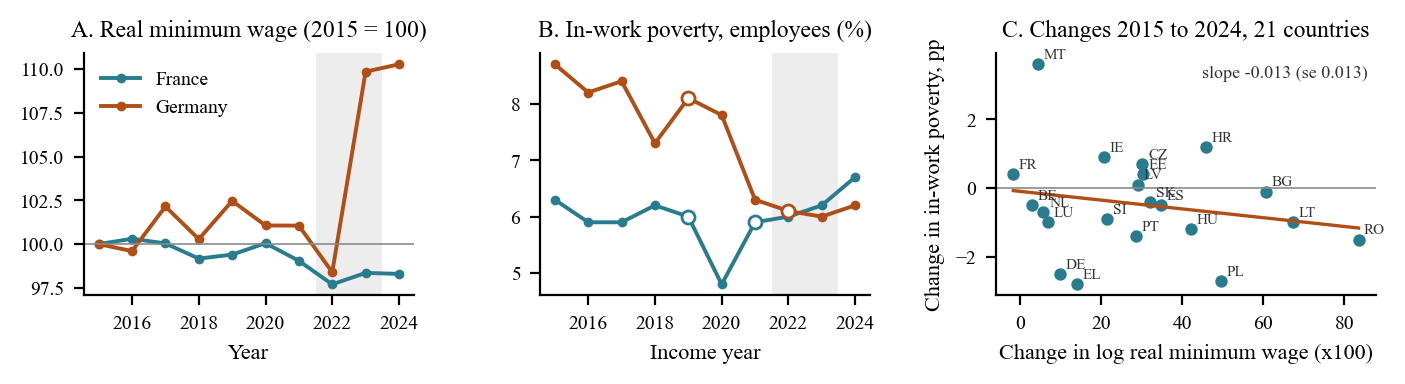

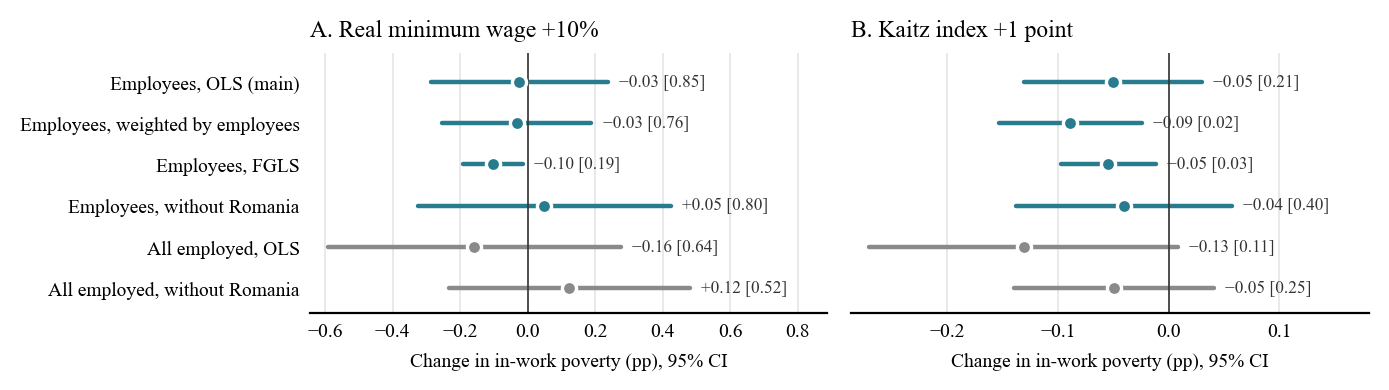

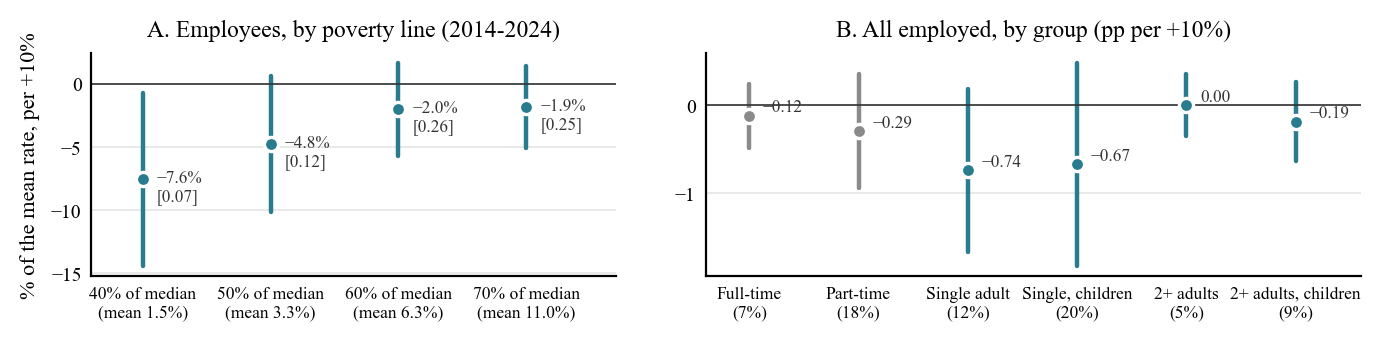

In [40]:
import subprocess
from IPython.display import Image, display

for script in ["make_tables.py", "make_figures.py"]:
    subprocess.run([sys.executable, script], cwd="report_code", check=True)
for name in ["fig1_motivation", "fig2_estimates", "fig3_mechanisms"]:
    display(Image(filename=f"output/figures/{name}.png"))